Natalia Cercós Olmos

# White dwarfs

Data: https://arxiv.org/pdf/1811.03084

Survey: https://skyserver.sdss.org/dr20/VisualTools/explore/summary?plate=2630&mjd=54327&fiber=359

In [1]:
pip install astropy

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

### 0387-51791-166

In [4]:
filename = "spec-7848-56959-0062.fits"

hdul = fits.open(filename)
hdul.info()

Filename: spec-7848-56959-0062.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     152   ()      
  1  COADD         1 BinTableHDU     26   4629R x 8C   [E, E, E, J, J, E, E, E]   
  2  SPALL         1 BinTableHDU    488   1R x 236C   [27A, 14A, 4A, E, E, J, J, E, J, E, E, E, K, K, K, K, K, K, K, K, K, B, B, J, I, 5E, 5E, J, J, J, J, 7A, 7A, 16A, D, D, 6A, 21A, E, E, E, J, E, 24A, 10J, J, 10E, E, E, E, E, E, E, J, E, E, E, J, 5E, E, E, 10E, 10E, 10E, 5E, 5E, 5E, 5E, 5E, J, J, E, E, E, E, E, E, 16A, 9A, 12A, E, E, E, E, E, E, E, E, J, E, E, J, J, 6A, 21A, E, 35E, K, 19A, 19A, 19A, B, B, B, I, 3A, B, I, I, I, I, J, E, J, J, E, E, E, E, E, E, E, E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5J, 5J, 5J, 5E, 5J, 75E, 75E, 5E, 5E, 5E, 5J, 5E, D, D, D, D, D, D, D, D, D, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E

In [5]:
data = hdul[1].data

print(data.names)

['flux', 'loglam', 'ivar', 'and_mask', 'or_mask', 'wdisp', 'sky', 'model']


In [6]:
wavelength = 10**data['loglam']
flux = data['flux']

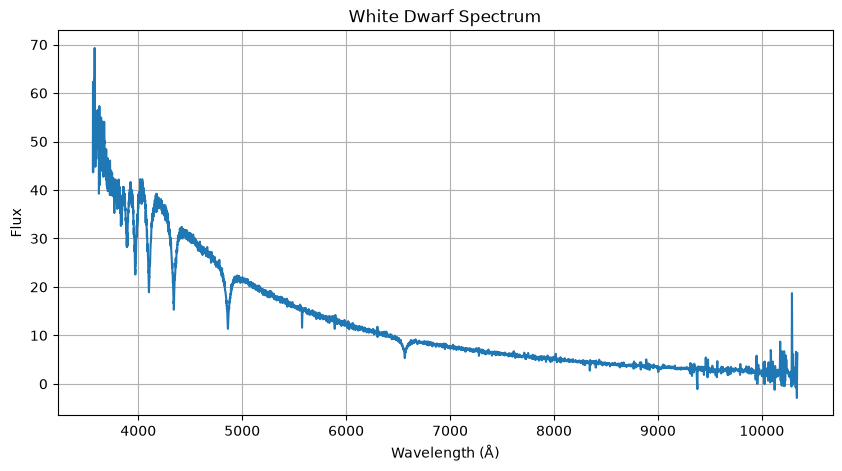

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(wavelength, flux)

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.title("White Dwarf Spectrum")

plt.grid()
plt.show()


**Identification of the Balmer Lines**

The next step is to identify the Balmer lines in the white dwarf spectrum. These lines correspond to electronic transitions in hydrogen from higher energy levels to $n=2$.

We will focus on four Balmer lines:

| Line | Wavelength (Å) |
|------|----------------|
| H$\alpha$ | 6562.8 |
| H$\beta$ | 4861.3 |
| H$\gamma$ | 4340.5 |
| H$\delta$ | 4101.7 |

In DA white dwarfs, these lines appear as absorption features. We will mark their theoretical wavelengths in the spectrum to identify their positions.

Later, we will use these lines to measure their strengths and construct the Boltzmann plot.


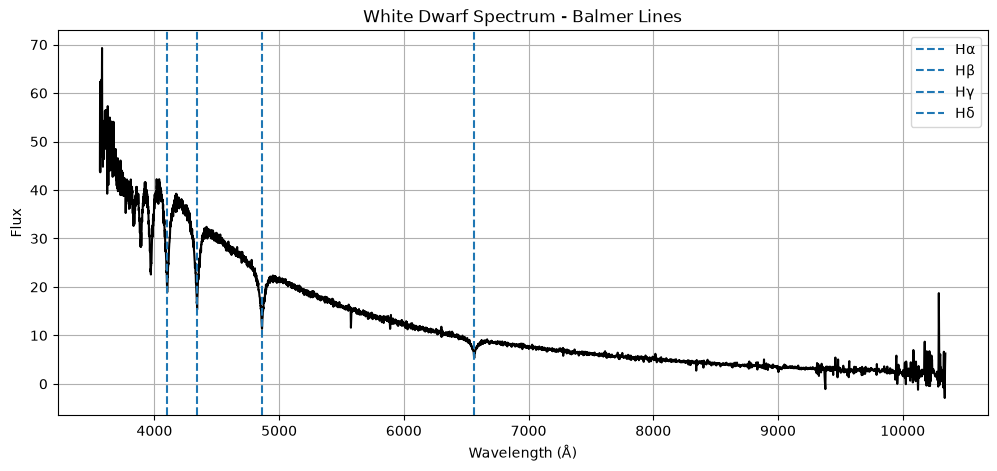

In [8]:
balmer_lines = {
    'Hα': 6562.8,
    'Hβ': 4861.3,
    'Hγ': 4340.5,
    'Hδ': 4101.7
}

plt.figure(figsize=(12, 5))

plt.plot(wavelength, flux, color='black')

for line, lam in balmer_lines.items():
    plt.axvline(lam, linestyle='--', label=line)

plt.xlabel('Wavelength (Å)')
plt.ylabel('Flux')
plt.title('White Dwarf Spectrum - Balmer Lines')

plt.legend()
plt.grid()
plt.show()


**Black Body fitting**

We fit a blackbody function to the continuum of the white dwarf spectrum to estimate its temperature.

First, we mask the Balmer absorption lines using a region of approximately $\pm 50$ Å around each line.

We use Planck's law:

$$
B_\lambda(T) = \frac{2hc^2}{\lambda^5}
\frac{1}{e^{hc/(\lambda k_B T)}-1}
$$

The model is:

$$
F_\lambda = A B_\lambda(T)
$$

The fit is performed using the unmasked regions of the spectrum.


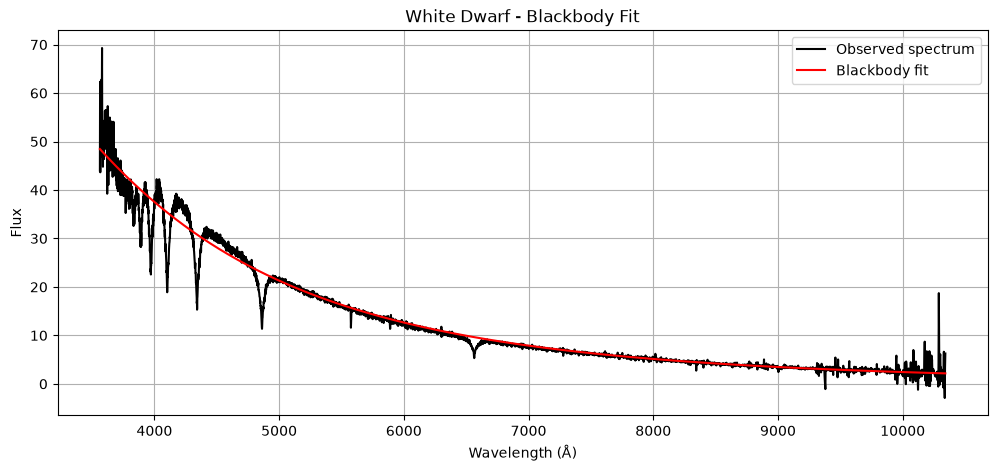

Blackbody temperature: 14770.19 K
Scaling factor: 3.3619e-14


In [12]:
from scipy.optimize import curve_fit
from scipy.constants import h, c, k

# Blackbody function
def blackbody(wavelength, T, A):
    lam = wavelength * 1e-10
    B = (2 * h * c**2 / lam**5) / np.expm1(h * c / (lam * k * T))
    return A * B

# Mask Balmer lines (±50 Å)
mask = np.ones(len(wavelength), dtype=bool)

for lam in balmer_lines.values():
    mask &= np.abs(wavelength - lam) > 50

mask &= np.isfinite(wavelength) & np.isfinite(flux)

# Initial values
T0 = 15000
A0 = np.max(flux[mask]) / np.max(blackbody(wavelength[mask], T0, 1))

# Fit
popt, pcov = curve_fit(
    blackbody,
    wavelength[mask],
    flux[mask],
    p0=[T0, A0],
    bounds=([3000, 0], [100000, np.inf]),
    maxfev=20000
)

T_bb, A_bb = popt
continuum = blackbody(wavelength, T_bb, A_bb)

# Plot
plt.figure(figsize=(12, 5))

plt.plot(wavelength, flux, color='black', label='Observed spectrum')
plt.plot(wavelength, continuum, color='red', label='Blackbody fit')

plt.xlabel('Wavelength (Å)')
plt.ylabel('Flux')
plt.title('White Dwarf - Blackbody Fit')

plt.legend()
plt.grid()
plt.show()

print(f"Blackbody temperature: {T_bb:.2f} K")
print(f"Scaling factor: {A_bb:.4e}")


**Spectrum Normalization**

After fitting the blackbody function, we normalize the observed spectrum by dividing the flux by the fitted continuum:

$$
F_{\mathrm{normalized}} = \frac{F_\lambda}{F_c}
$$

where $F_\lambda$ is the observed flux and $F_c$ is the continuum obtained from the blackbody fit.

This allows us to measure the absorption lines relative to the continuum, which should be approximately equal to 1.

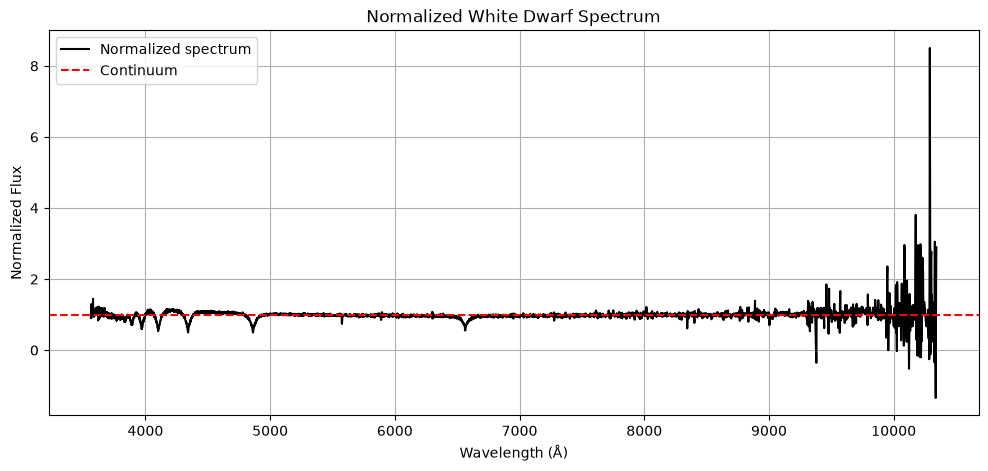

In [13]:

# Normalize the spectrum
normalized_flux = flux / continuum

# Plot
plt.figure(figsize=(12, 5))

plt.plot(wavelength, normalized_flux, color='black',
         label='Normalized spectrum')

plt.axhline(1, color='red', linestyle='--',
            label='Continuum')

plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalized Flux')
plt.title('Normalized White Dwarf Spectrum')

plt.legend()
plt.grid()
plt.show()


**Equivalent Widths**

We calculate the equivalent width (EW) of each Balmer absorption line using the normalized spectrum.

The equivalent width is defined as:

$$
W_\lambda = \int_{\lambda_1}^{\lambda_2}
\left(1-\frac{F_\lambda}{F_c}\right)d\lambda
$$

where $F_\lambda$ is the observed flux and $F_c$ is the continuum obtained from the blackbody fit.

We use a window of $\pm 50$ Å around each Balmer line and calculate the integral numerically. The equivalent widths are expressed in Å.


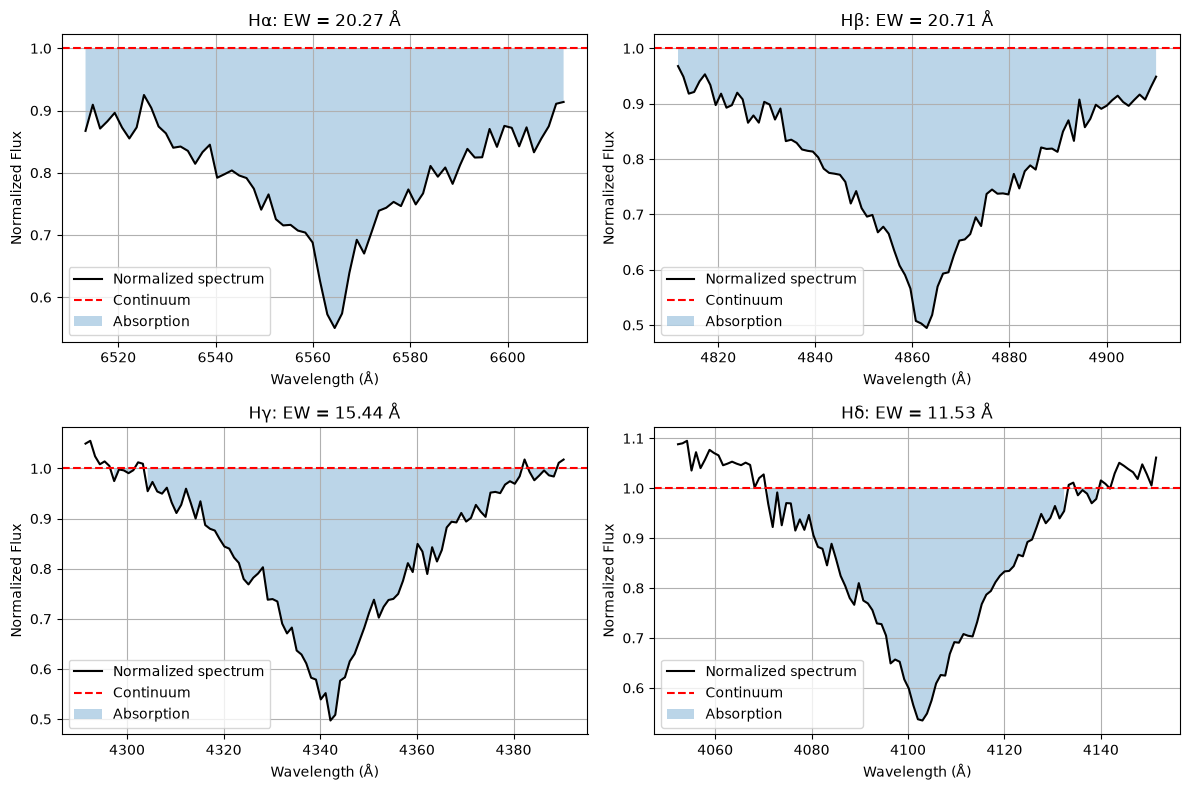

Hα: 20.27 Å
Hβ: 20.71 Å
Hγ: 15.44 Å
Hδ: 11.53 Å


In [14]:
# Calculate equivalent widths
equivalent_widths = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (line, lam) in zip(axes.flat, balmer_lines.items()):

    # Select region around each line
    mask = (wavelength >= lam - 50) & (wavelength <= lam + 50)

    x = wavelength[mask]
    y = normalized_flux[mask]

    # Equivalent width
    W = np.trapezoid(1 - y, x)
    equivalent_widths[line] = W

    # Plot
    ax.plot(x, y, color='black', label='Normalized spectrum')
    ax.axhline(1, color='red', linestyle='--', label='Continuum')

    ax.fill_between(x, y, 1, where=(y < 1),
                    alpha=0.3, label='Absorption')

    ax.set_title(f'{line}: EW = {W:.2f} Å')
    ax.set_xlabel('Wavelength (Å)')
    ax.set_ylabel('Normalized Flux')
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

# Print results
for line, W in equivalent_widths.items():
    print(f'{line}: {W:.2f} Å')


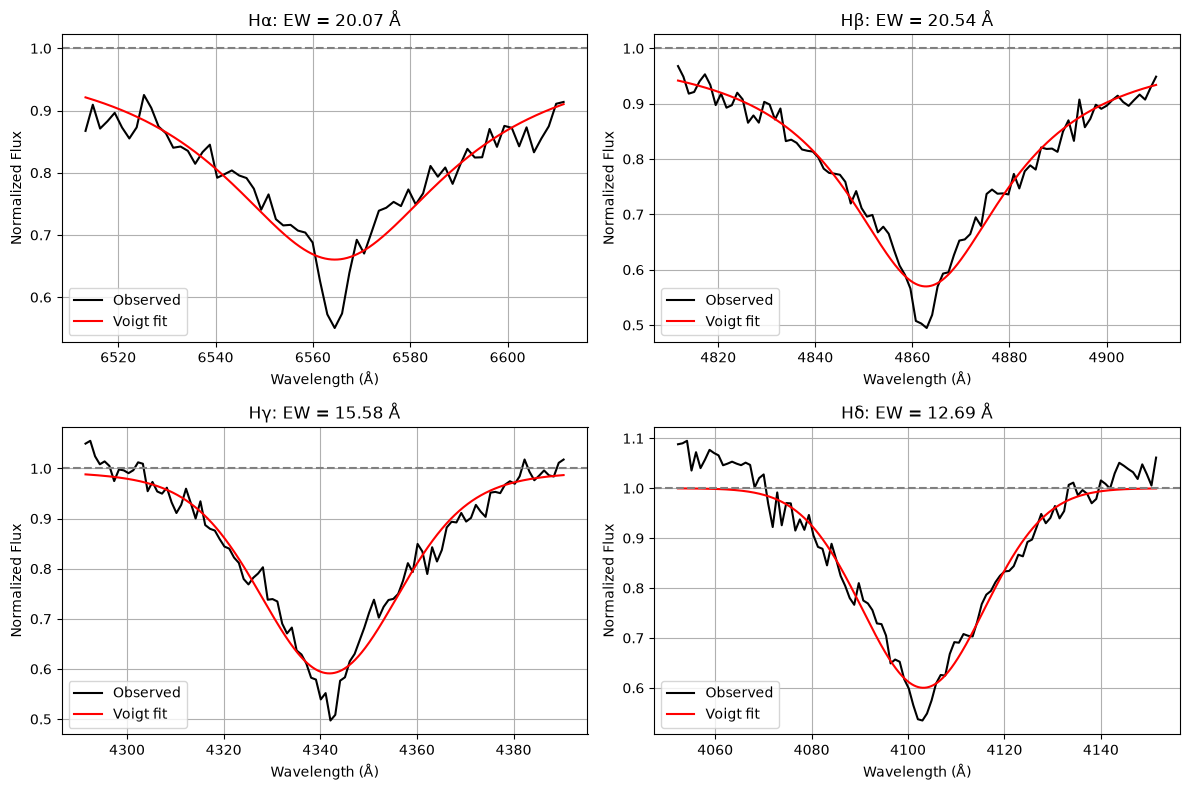

Hα: 20.07 Å
Hβ: 20.54 Å
Hγ: 15.58 Å
Hδ: 12.69 Å


In [25]:

from scipy.special import voigt_profile
from scipy.optimize import curve_fit

def absorption_voigt(x, center, depth, sigma, gamma):
    profile = voigt_profile(x - center, sigma, gamma)
    profile = profile / voigt_profile(0, sigma, gamma)
    return 1 - depth * profile

equivalent_widths = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (line, lam0) in zip(axes.flat, balmer_lines.items()):

    mask = (
        (wavelength >= lam0 - 50) &
        (wavelength <= lam0 + 50) &
        np.isfinite(normalized_flux)
    )

    x = wavelength[mask]
    y = normalized_flux[mask]

    p0 = [lam0, np.clip(1 - np.min(y), 0.01, 1), 5, 5]

    bounds = (
        [lam0 - 10, 0, 0.1, 0.1],
        [lam0 + 10, 1, 40, 40]
    )

    popt, _ = curve_fit(
        absorption_voigt, x, y,
        p0=p0, bounds=bounds,
        maxfev=20000
    )

    x_fit = np.linspace(x.min(), x.max(), 2000)
    y_fit = absorption_voigt(x_fit, *popt)

    W = np.trapezoid(1 - y_fit, x_fit)
    equivalent_widths[line] = W

    ax.plot(x, y, color='black', label='Observed')
    ax.plot(x_fit, y_fit, color='red', label='Voigt fit')
    ax.axhline(1, color='gray', linestyle='--')

    ax.set_title(f'{line}: EW = {W:.2f} Å')
    ax.set_xlabel('Wavelength (Å)')
    ax.set_ylabel('Normalized Flux')
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

for line, W in equivalent_widths.items():
    print(f'{line}: {W:.2f} Å')


**Boltzmann Plot**

We use the measured equivalent widths of the four Balmer absorption lines and the atomic data to examine their relationship with the upper-level energies.

The expression from the class notes is:

$$
\ln\left(\frac{I_{jk}\lambda_{jk}}{g_k A_{jk}}\right)
= -\frac{E_k}{k_B T_{\mathrm{exc}}}+C
$$

This equation is derived for emission-line intensities. Since our measurements are equivalent widths of absorption lines, we first examine the resulting trend without assuming that its slope gives a valid excitation temperature.


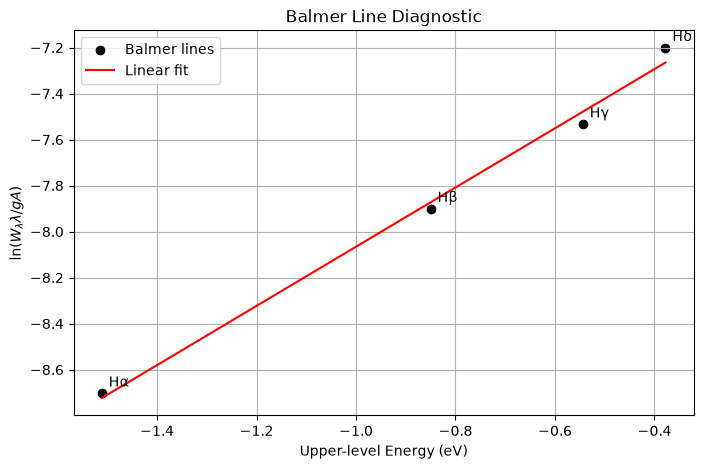

Slope: 1.2871 eV^-1
Blackbody temperature: 14770.19 K


In [26]:

# Atomic data
lines = ['Hα', 'Hβ', 'Hγ', 'Hδ']

n = np.array([3, 4, 5, 6])
lam = np.array([6562.8, 4861.3, 4340.5, 4101.7])
g = 2 * n**2

A = np.array([4.410, 0.842, 0.253, 0.097]) * 1e7
E = np.array([-1.511, -0.850, -0.544, -0.378])

W = np.array([equivalent_widths[line] for line in lines])

# Equivalent-width-based diagnostic
y = np.log(W * lam / (g * A))

# Linear fit
alpha, beta = np.polyfit(E, y, 1)

plt.figure(figsize=(8, 5))

plt.scatter(E, y, color='black', label='Balmer lines')
plt.plot(E, alpha * E + beta, color='red',
         label='Linear fit')

for i, line in enumerate(lines):
    plt.annotate(line, (E[i], y[i]),
                 xytext=(5, 5), textcoords='offset points')

plt.xlabel('Upper-level Energy (eV)')
plt.ylabel(r'$\ln(W_\lambda \lambda / gA)$')
plt.title('Balmer Line Diagnostic')

plt.legend()
plt.grid()
plt.show()

print(f"Slope: {alpha:.4f} eV^-1")
print(f"Blackbody temperature: {T_bb:.2f} K")


In [27]:

# Excitation temperature
k_B = 8.617333262e-5  # eV/K

T_exc = -1 / (k_B * alpha)

print(f"Slope: {alpha:.4f}")
print(f"Excitation temperature: {T_exc:.2f} K")
print(f"Blackbody temperature: {T_bb:.2f} K")


Slope: 1.2871
Excitation temperature: -9016.30 K
Blackbody temperature: 14770.19 K


###  2624-54380-261

In [39]:
filename = "spec-7034-56564-0336.fits"

hdul = fits.open(filename)
hdul.info()

Filename: spec-7034-56564-0336.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     125   ()      
  1  COADD         1 BinTableHDU     26   4627R x 8C   [E, E, E, J, J, E, E, E]   
  2  SPALL         1 BinTableHDU    488   1R x 236C   [27A, 14A, 4A, E, E, J, J, E, J, E, E, E, K, K, K, K, K, K, K, K, K, B, B, J, I, 5E, 5E, J, J, J, J, 7A, 7A, 16A, D, D, 6A, 21A, E, E, E, J, E, 24A, 10J, J, 10E, E, E, E, E, E, E, J, E, E, E, J, 5E, E, E, 10E, 10E, 10E, 5E, 5E, 5E, 5E, 5E, J, J, E, E, E, E, E, E, 16A, 9A, 12A, E, E, E, E, E, E, E, E, J, E, E, J, J, 6A, 21A, E, 35E, K, 19A, 19A, 19A, B, B, B, I, 3A, B, I, I, I, I, J, E, J, J, E, E, E, E, E, E, E, E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5J, 5J, 5J, 5E, 5J, 75E, 75E, 5E, 5E, 5E, 5J, 5E, D, D, D, D, D, D, D, D, D, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E

In [40]:
wavelength = 10**data['loglam']
flux = data['flux']

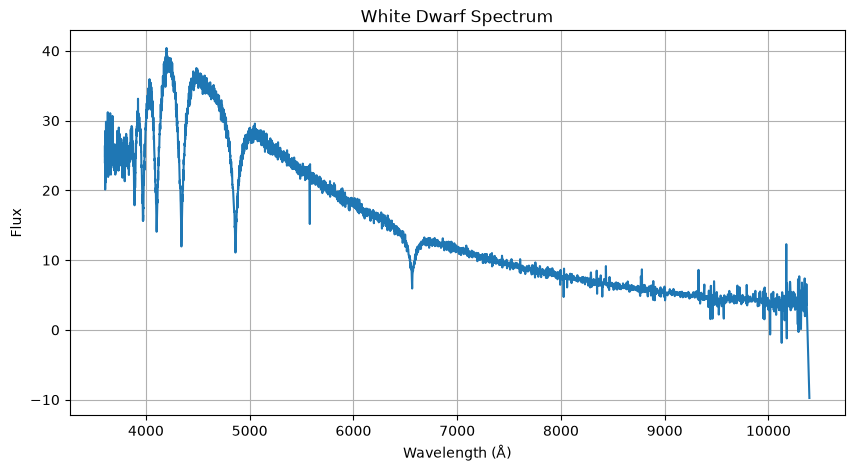

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(wavelength, flux)

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.title("White Dwarf Spectrum")

plt.grid()
plt.show()

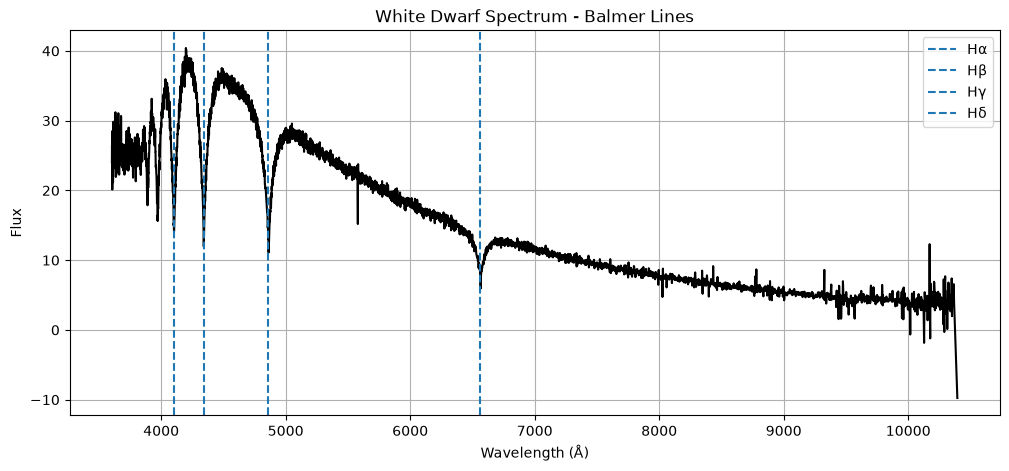

In [42]:
balmer_lines = {
    'Hα': 6562.8,
    'Hβ': 4861.3,
    'Hγ': 4340.5,
    'Hδ': 4101.7
}

plt.figure(figsize=(12, 5))

plt.plot(wavelength, flux, color='black')

for line, lam in balmer_lines.items():
    plt.axvline(lam, linestyle='--', label=line)

plt.xlabel('Wavelength (Å)')
plt.ylabel('Flux')
plt.title('White Dwarf Spectrum - Balmer Lines')

plt.legend()
plt.grid()
plt.show()


In [44]:
# Normalize the spectrum
normalized_flux_1 = flux / continuum

# Plot
plt.figure(figsize=(12, 5))

plt.plot(wavelength, normalized_flux_1, color='black',
         label='Normalized spectrum')

plt.axhline(1, color='red', linestyle='--',
            label='Continuum')

plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalized Flux')
plt.title('Normalized White Dwarf Spectrum')

plt.legend()
plt.grid()
plt.show()


ValueError: operands could not be broadcast together with shapes (4601,) (4629,) 

IndexError: boolean index did not match indexed array along axis 0; size of axis is 4629 but size of corresponding boolean axis is 4601

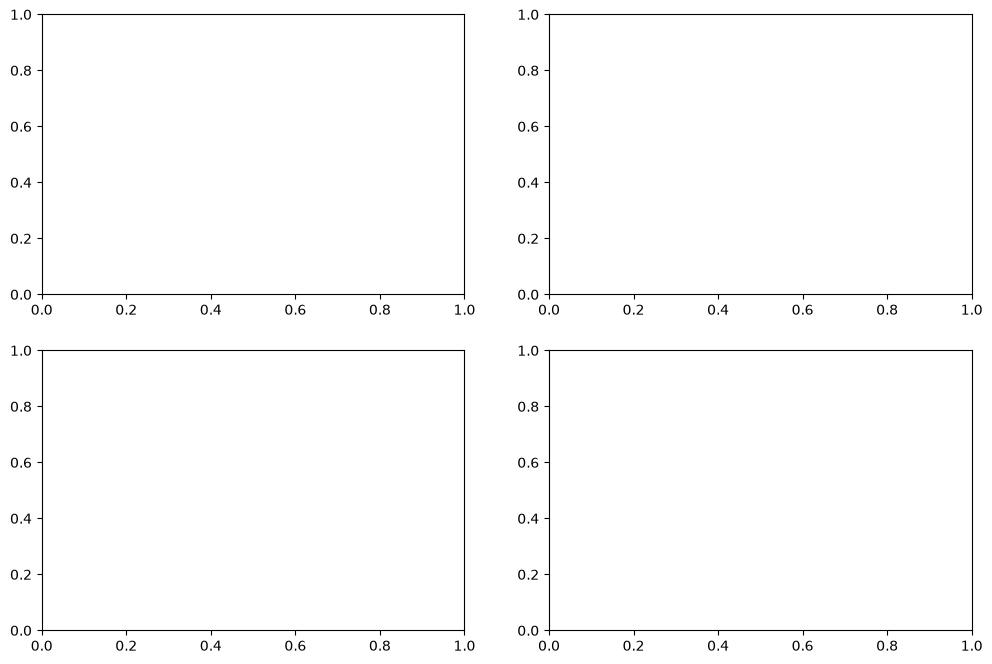

In [45]:
# Calculate equivalent widths
equivalent_widths = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (line, lam) in zip(axes.flat, balmer_lines.items()):

    # Select region around each line
    mask = (wavelength >= lam - 50) & (wavelength <= lam + 50)

    x = wavelength[mask]
    y = normalized_flux[mask]

    # Equivalent width
    W = np.trapezoid(1 - y, x)
    equivalent_widths[line] = W

    # Plot
    ax.plot(x, y, color='black', label='Normalized spectrum')
    ax.axhline(1, color='red', linestyle='--', label='Continuum')

    ax.fill_between(x, y, 1, where=(y < 1),
                    alpha=0.3, label='Absorption')

    ax.set_title(f'{line}: EW = {W:.2f} Å')
    ax.set_xlabel('Wavelength (Å)')
    ax.set_ylabel('Normalized Flux')
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

# Print results
for line, W in equivalent_widths.items():
    print(f'{line}: {W:.2f} Å')


### 0685-52203-187

In [34]:
filename = "spec-7850-56956-0688.fits"

hdul = fits.open(filename)
hdul.info()

Filename: spec-7850-56956-0688.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     126   ()      
  1  COADD         1 BinTableHDU     26   4601R x 8C   [E, E, E, J, J, E, E, E]   
  2  SPALL         1 BinTableHDU    488   1R x 236C   [27A, 14A, 4A, E, E, J, J, E, J, E, E, E, K, K, K, K, K, K, K, K, K, B, B, J, I, 5E, 5E, J, J, J, J, 7A, 7A, 16A, D, D, 6A, 21A, E, E, E, J, E, 24A, 10J, J, 10E, E, E, E, E, E, E, J, E, E, E, J, 5E, E, E, 10E, 10E, 10E, 5E, 5E, 5E, 5E, 5E, J, J, E, E, E, E, E, E, 16A, 9A, 12A, E, E, E, E, E, E, E, E, J, E, E, J, J, 6A, 21A, E, 35E, K, 19A, 19A, 19A, B, B, B, I, 3A, B, I, I, I, I, J, E, J, J, E, E, E, E, E, E, E, E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5J, 5J, 5J, 5E, 5J, 75E, 75E, 5E, 5E, 5E, 5J, 5E, D, D, D, D, D, D, D, D, D, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E

In [35]:
data = hdul[1].data

print(data.names)

['flux', 'loglam', 'ivar', 'and_mask', 'or_mask', 'wdisp', 'sky', 'model']


In [36]:
wavelength = 10**data['loglam']
flux = data['flux']

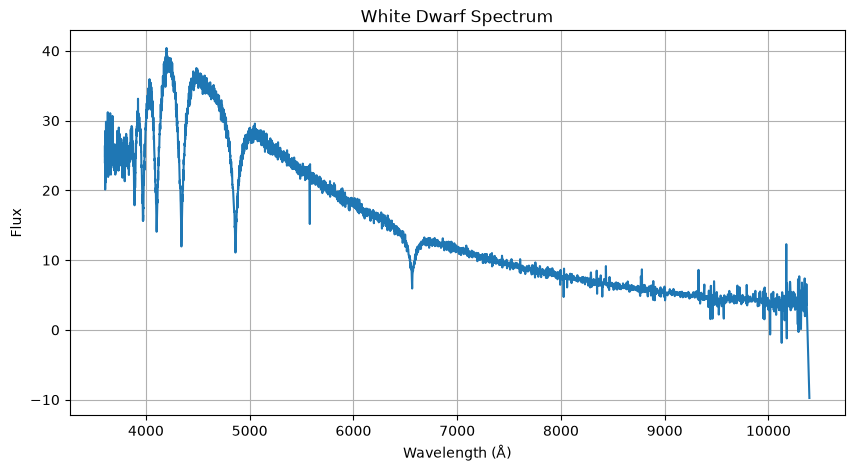

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(wavelength, flux)

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.title("White Dwarf Spectrum")

plt.grid()
plt.show()

### 2824-54452-272

In [38]:
filename = "spec-7695-57654-0618.fits"

hdul = fits.open(filename)
hdul.info()

Filename: spec-7695-57654-0618.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     138   ()      
  1  COADD         1 BinTableHDU     26   4585R x 8C   [E, E, E, J, J, E, E, E]   
  2  SPALL         1 BinTableHDU    488   1R x 236C   [27A, 14A, 4A, E, E, J, J, E, J, E, E, E, K, K, K, K, K, K, K, K, K, B, B, J, I, 5E, 5E, J, J, J, J, 7A, 7A, 16A, D, D, 6A, 21A, E, E, E, J, E, 24A, 10J, J, 10E, E, E, E, E, E, E, J, E, E, E, J, 5E, E, E, 10E, 10E, 10E, 5E, 5E, 5E, 5E, 5E, J, J, E, E, E, E, E, E, 16A, 9A, 12A, E, E, E, E, E, E, E, E, J, E, E, J, J, 6A, 21A, E, 35E, K, 19A, 19A, 19A, B, B, B, I, 3A, B, I, I, I, I, J, E, J, J, E, E, E, E, E, E, E, E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5J, 5J, 5J, 5E, 5J, 75E, 75E, 5E, 5E, 5E, 5J, 5E, D, D, D, D, D, D, D, D, D, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E

In [16]:
data = hdul[1].data

print(data.names)

['flux', 'loglam', 'ivar', 'and_mask', 'or_mask', 'wdisp', 'sky', 'model']


In [17]:
wavelength = 10**data['loglam']
flux = data['flux']

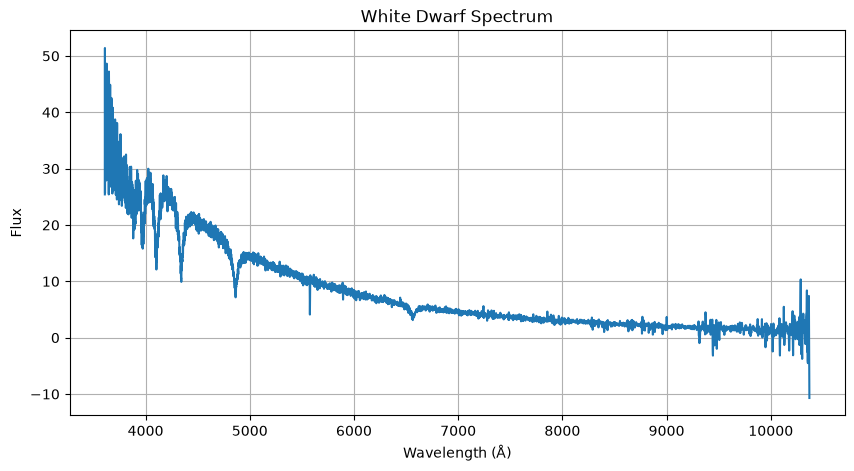

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(wavelength, flux)

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.title("White Dwarf Spectrum")

plt.grid()
plt.show()

### 2630-54327-359

In [19]:
filename = "spec-7895-57659-0088.fits"

hdul = fits.open(filename)
hdul.info()

Filename: spec-7895-57659-0088.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     142   ()      
  1  COADD         1 BinTableHDU     26   4615R x 8C   [E, E, E, J, J, E, E, E]   
  2  SPALL         1 BinTableHDU    488   1R x 236C   [27A, 14A, 4A, E, E, J, J, E, J, E, E, E, K, K, K, K, K, K, K, K, K, B, B, J, I, 5E, 5E, J, J, J, J, 7A, 7A, 16A, D, D, 6A, 21A, E, E, E, J, E, 24A, 10J, J, 10E, E, E, E, E, E, E, J, E, E, E, J, 5E, E, E, 10E, 10E, 10E, 5E, 5E, 5E, 5E, 5E, J, J, E, E, E, E, E, E, 16A, 9A, 12A, E, E, E, E, E, E, E, E, J, E, E, J, J, 6A, 21A, E, 35E, K, 19A, 19A, 19A, B, B, B, I, 3A, B, I, I, I, I, J, E, J, J, E, E, E, E, E, E, E, E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5J, 5J, 5J, 5E, 5J, 75E, 75E, 5E, 5E, 5E, 5J, 5E, D, D, D, D, D, D, D, D, D, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E, 5E

In [20]:
data = hdul[1].data

print(data.names)

['flux', 'loglam', 'ivar', 'and_mask', 'or_mask', 'wdisp', 'sky', 'model']


In [21]:
wavelength = 10**data['loglam']
flux = data['flux']

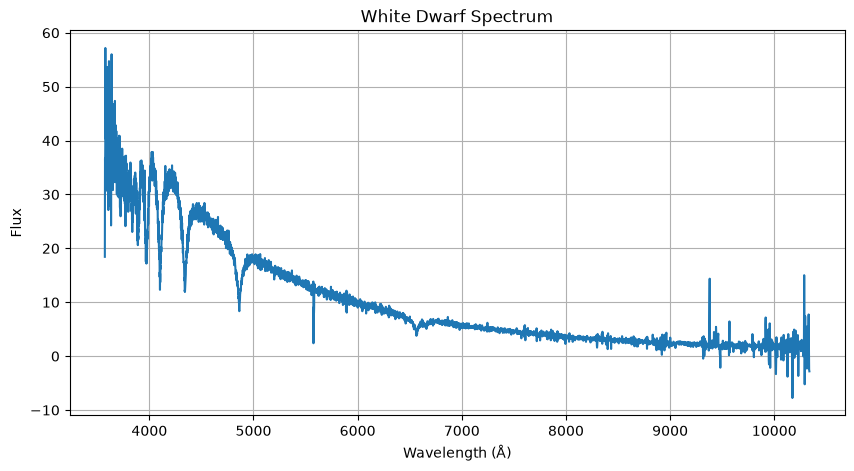

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(wavelength, flux)

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.title("White Dwarf Spectrum")

plt.grid()
plt.show()